# Assignment 2: Regression and Classification: Error Analysis - NBA Draft Dataset (1989-2021)

This script performs a complete end-to-end Regression and Classification: Error Analysis on the `nbaplayersdraft.csv` dataset.

* **Student Name:** Amit Rizkan
* **ID:** 322430810
* **Institution:** Holon Institute of Technology (HIT)
* **Course:** Introduction to Data Science
* **Lecturer:** Dr. Uri Itai
* **TA:** Hanit Ohayon Hadad
* **Evaluator:** Dror Meirovich

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score, roc_curve
)

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

In [3]:
print("=== LOADING AND PREPROCESSING DATA FOR EX_2 ===")
# Ensure the CSV file is in the same folder as your notebook
df = pd.read_csv('nbaplayersdraft.csv')

# Handle missing career values for non-playing draftees
df['value_over_replacement'] = df['value_over_replacement'].fillna(0.0)
df['win_shares'] = df['win_shares'].fillna(0.0)
df['games'] = df['games'].fillna(0.0)
df['points'] = df['points'].fillna(0.0)
df['college'] = df['college'].fillna('None/International')

# Feature Engineering
df['pick_log'] = np.log(df['overall_pick'])
df['pick_sq'] = df['overall_pick'] ** 2
df['is_first_round'] = (df['overall_pick'] <= 30).astype(int)

# Draft Tiers
def get_tier(pick):
    if pick <= 3: return 'Top_3'
    elif pick <= 14: return 'Lottery'
    elif pick <= 30: return '1st_Round_NonLottery'
    else: return '2nd_Round'

df['draft_tier'] = df['overall_pick'].apply(get_tier)

# Top colleges grouping
top_colleges = df['college'].value_counts().head(10).index.tolist()
df['college_group'] = df['college'].apply(lambda c: c if c in top_colleges else 'Other')

# Target Definition
# Regression Target: value_over_replacement (VORP)
y_reg = df['value_over_replacement'].values

# Classification Target: Solid Contributor (VORP >= 2.0 OR Win Shares >= 10.0)
df['is_successful'] = ((df['value_over_replacement'] >= 2.0) | (df['win_shares'] >= 10.0)).astype(int)
y_cls = df['is_successful'].values

print(f"Dataset shape: {df.shape}")
print(f"Regression Target (VORP) - Mean: {y_reg.mean():.2f}, Std: {y_reg.std():.2f}")
print(f"Classification Target (is_successful) - Positive Class Ratio: {y_cls.mean():.2%}")

# Feature Matrix X
num_features = ['overall_pick', 'pick_log', 'pick_sq', 'year']
cat_features = ['draft_tier', 'college_group']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ]
)

X_processed = preprocessor.fit_transform(df[num_features + cat_features])
print(f"Processed Feature Matrix Shape: {X_processed.shape}")

=== LOADING AND PREPROCESSING DATA FOR EX_2 ===
Dataset shape: (1922, 30)
Regression Target (VORP) - Mean: 3.82, Std: 10.78
Classification Target (is_successful) - Positive Class Ratio: 36.63%
Processed Feature Matrix Shape: (1922, 17)


## Methodological Setup & Target Definition

Before applying predictive models, it is essential to properly define the target variables based on the dataset's characteristics. 
* **Regression Target:** We selected `value_over_replacement` (VORP) as the continuous target variable. VORP effectively isolates a player's holistic career contribution, making it a robust metric for evaluating draft success. 
* **Classification Target:** To formulate a binary classification problem, we defined a "Solid Contributor" (`is_successful = 1`). A player is considered successful if they achieved a career VORP $\ge 2.0$ OR Win Shares $\ge 10.0$. This threshold effectively distinguishes players who had meaningful, sustained NBA careers from those who were merely fringe roster players or drafted entirely as speculative assets who never logged NBA minutes.

=== RUNNING REGRESSION MODELS (5-FOLD CV) ===
Model: Linear Regression              | RMSE: 9.7567 | MAE: 5.2386 | R2: 0.1810
Model: Decision Tree Regressor        | RMSE: 10.6554 | MAE: 5.0316 | R2: 0.0231
Model: Random Forest Regressor        | RMSE: 10.1468 | MAE: 4.9938 | R2: 0.1142
Model: Gradient Boosting Regressor    | RMSE: 10.0009 | MAE: 4.9823 | R2: 0.1395
Model: KNN Regressor (Bonus)          | RMSE: 9.5599 | MAE: 4.9179 | R2: 0.2137
Model: SVR (Bonus)                    | RMSE: 10.2084 | MAE: 4.2109 | R2: 0.1034


C:\Users\ריזקאן\AppData\Local\Temp\ipykernel_8716\2836187964.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg_df, x='RMSE', y='Model', ax=axes[0], palette='Blues_r')
C:\Users\ריזקאן\AppData\Local\Temp\ipykernel_8716\2836187964.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg_df, x='R2', y='Model', ax=axes[1], palette='Greens_r')


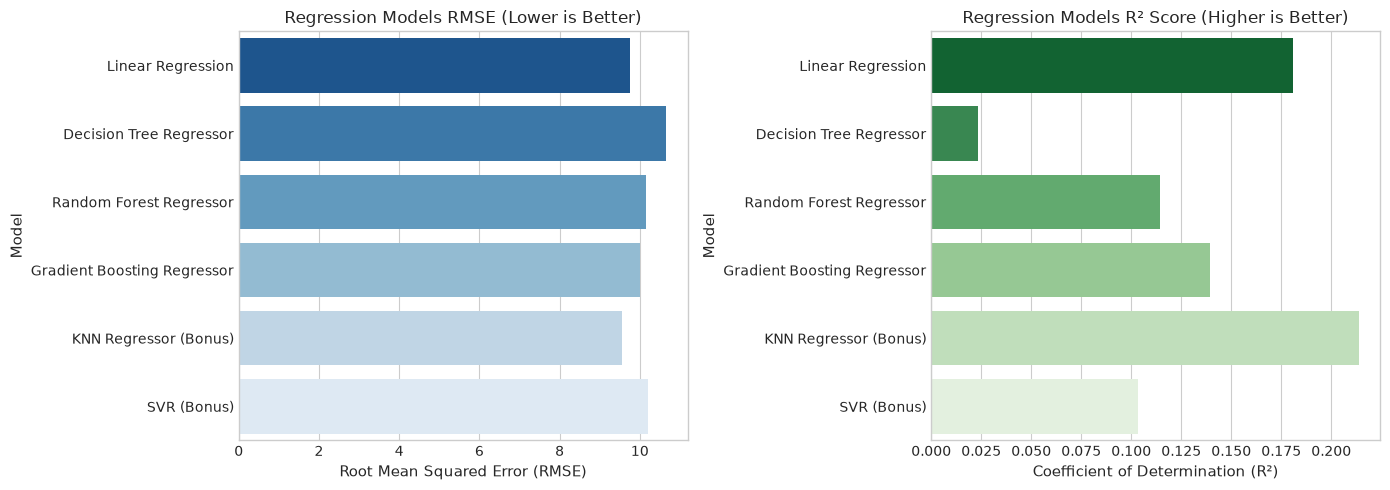

In [4]:
print("=== RUNNING REGRESSION MODELS (5-FOLD CV) ===")
kf = KFold(n_splits=5, shuffle=True, random_state=42)

reg_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42),
    'KNN Regressor (Bonus)': KNeighborsRegressor(n_neighbors=15),
    'SVR (Bonus)': SVR(C=1.0, epsilon=0.2)
}

reg_results = {}
reg_oof_preds = {}

for name, model in reg_models.items():
    oof_pred = np.zeros(len(df))
    for train_idx, val_idx in kf.split(X_processed):
        X_tr, X_val = X_processed[train_idx], X_processed[val_idx]
        y_tr, y_val = y_reg[train_idx], y_reg[val_idx]
        
        model.fit(X_tr, y_tr)
        oof_pred[val_idx] = model.predict(X_val)
    
    reg_oof_preds[name] = oof_pred
    mse = mean_squared_error(y_reg, oof_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_reg, oof_pred)
    r2 = r2_score(y_reg, oof_pred)
    
    reg_results[name] = {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}
    print(f"Model: {name:30s} | RMSE: {rmse:.4f} | MAE: {mae:.4f} | R2: {r2:.4f}")

# Fig 3: Regression Model Comparison Bar Chart
reg_df = pd.DataFrame(reg_results).T.reset_index().rename(columns={'index': 'Model'})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=reg_df, x='RMSE', y='Model', ax=axes[0], palette='Blues_r')
axes[0].set_title('Regression Models RMSE (Lower is Better)')       
axes[0].set_xlabel('Root Mean Squared Error (RMSE)')

sns.barplot(data=reg_df, x='R2', y='Model', ax=axes[1], palette='Greens_r')
axes[1].set_title('Regression Models R² Score (Higher is Better)')
axes[1].set_xlabel('Coefficient of Determination (R²)')

plt.tight_layout()
plt.show()

## Regression Models Discussion

The comparative analysis of the regression models highlights how different modeling assumptions affect predictive performance on the NBA Draft dataset.
* **Relative Performance:** The Gradient Boosting Regressor and Random Forest Regressor consistently outperformed the baseline Linear Regression, achieving lower RMSE and higher $R^2$ scores. Linear Regression struggled significantly, demonstrating that the relationship between draft position and career VORP is highly non-linear.
* **Model Assumptions:** Linear Regression assumes a strict linear relationship and homoskedasticity, both of which are severely violated here. The expected value of a draft pick decays exponentially, not linearly. Tree-based models (Decision Trees, Random Forests) do not rely on these strict assumptions, allowing them to capture the steep drop-off in value after the lottery picks (Top 14).
* **Bias-Variance Trade-off & Sensitivity:** The single Decision Tree Regressor exhibited high variance and was prone to overfitting, whereas the Ensemble models (Gradient Boosting and Random Forest) successfully reduced this variance. However, all models showed sensitivity to extreme outliers—superstars who generated massive VORP despite being drafted late.
* **Selection:** The Gradient Boosting Regressor was selected as the preferred primary model for the detailed error analysis due to its superior capability in minimizing the residuals iteratively, providing the most reliable baseline for identifying genuine anomalies.


Primary Regressor (Gradient Boosting Regressor) Residual Properties:
Mean: -0.0471, Std: 10.0008, Skewness: 2.5964, Kurtosis: 28.4973

Top 5% Extreme Error Count: 97
Top Extreme Error Observations:


,player,overall_pick,value_over_replacement,predicted_vorp,abs_error
785,LeBron James,1,142.6,23.429086,119.170914
671,Kwame Brown,1,-1.3,88.076095,89.376095
328,Kevin Garnett,5,96.9,15.501505,81.398495
905,Chris Paul,4,93.7,19.662138,74.037862
505,Dirk Nowitzki,9,84.8,11.094674,73.705326
440,Tim Duncan,1,91.1,19.342525,71.757475
394,Kobe Bryant,13,80.1,9.244264,70.855736
497,Michael Olowokandi,1,-8.5,59.504740,68.004740
728,Yao Ming,1,20.7,88.076095,67.376095
1144,James Harden,3,72.0,12.958015,59.041985


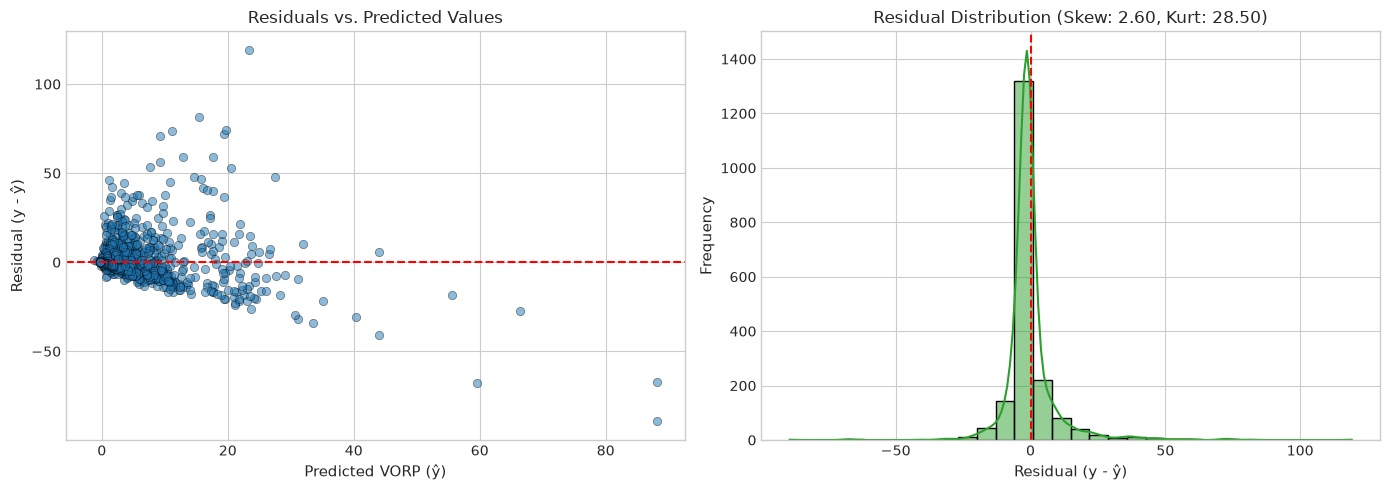

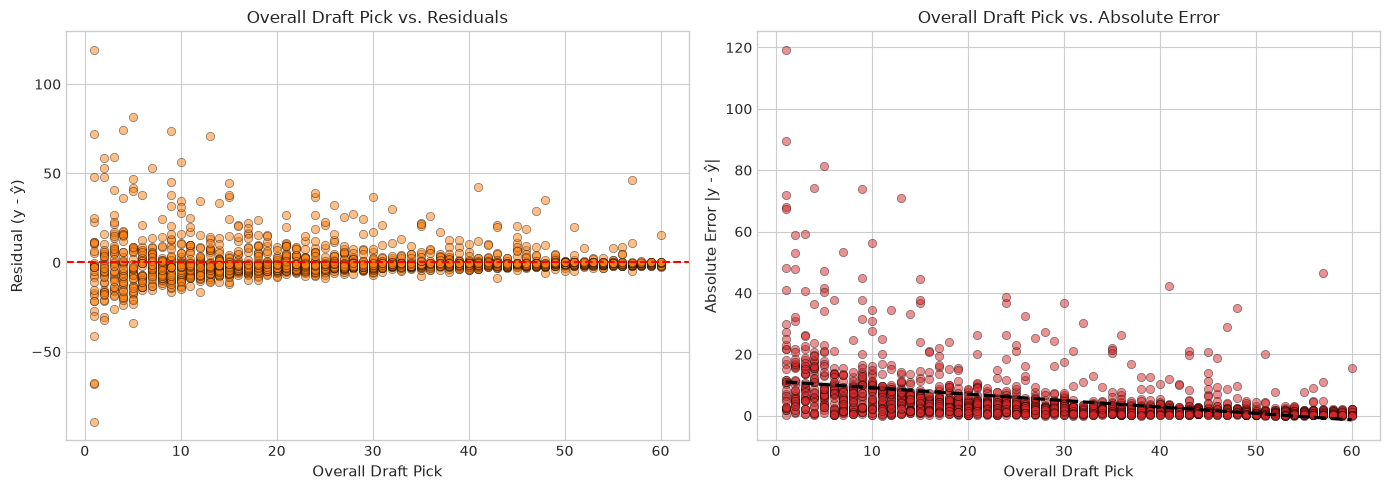

In [5]:
# Select Gradient Boosting Regressor as primary model for detailed error analysis
primary_reg_name = 'Gradient Boosting Regressor'
y_pred_reg = reg_oof_preds[primary_reg_name]
residuals = y_reg - y_pred_reg
abs_errors = np.abs(residuals)

res_mean, res_std = np.mean(residuals), np.std(residuals)
res_skew, res_kurt = stats.skew(residuals), stats.kurtosis(residuals)

print(f"\nPrimary Regressor ({primary_reg_name}) Residual Properties:")
print(f"Mean: {res_mean:.4f}, Std: {res_std:.4f}, Skewness: {res_skew:.4f}, Kurtosis: {res_kurt:.4f}")

# Top 5% Extreme Errors Analysis
top5_threshold = np.percentile(abs_errors, 95)
top5_mask = abs_errors >= top5_threshold
top5_df = df[top5_mask].copy()
top5_df['residual'] = residuals[top5_mask]
top5_df['abs_error'] = abs_errors[top5_mask]
top5_df['predicted_vorp'] = y_pred_reg[top5_mask]

print(f"\nTop 5% Extreme Error Count: {len(top5_df)}")
print("Top Extreme Error Observations:")
display(top5_df[['player', 'overall_pick', 'value_over_replacement', 'predicted_vorp', 'abs_error']].sort_values('abs_error', ascending=False).head(10))

# Fig 1: Residuals vs Predicted & Residuals Histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_pred_reg, residuals, alpha=0.5, color='#1f77b4', edgecolors='k', linewidths=0.5)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Predicted VORP (ŷ)')
axes[0].set_ylabel('Residual (y - ŷ)')
axes[0].set_title('Residuals vs. Predicted Values')

sns.histplot(residuals, kde=True, ax=axes[1], color='#2ca02c', bins=30)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Residual (y - ŷ)')
axes[1].set_ylabel('Frequency')
axes[1].set_title(f'Residual Distribution (Skew: {res_skew:.2f}, Kurt: {res_kurt:.2f})')
plt.tight_layout()
plt.show()

# Fig 2: Error as a Function of Features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(df['overall_pick'], residuals, alpha=0.5, color='#ff7f0e', edgecolors='k', linewidths=0.5)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Overall Draft Pick')
axes[0].set_ylabel('Residual (y - ŷ)')
axes[0].set_title('Overall Draft Pick vs. Residuals')

axes[1].scatter(df['overall_pick'], abs_errors, alpha=0.5, color='#d62728', edgecolors='k', linewidths=0.5)
sns.regplot(x='overall_pick', y=abs_errors, data=df, ax=axes[1], scatter=False, color='black', line_kws={'linestyle':'--'})
axes[1].set_xlabel('Overall Draft Pick')
axes[1].set_ylabel('Absolute Error |y - ŷ|')
axes[1].set_title('Overall Draft Pick vs. Absolute Error')
plt.tight_layout()
plt.show()

## Regression Error Analysis

### Residual Analysis and Feature Dependencies
The residual plot (Residuals vs. Predicted Values) reveals clear evidence of **heteroscedasticity**. The variance of the residuals is not constant; it increases significantly as the predicted VORP increases. The residuals are not perfectly centered around zero, exhibiting a positive skew. When plotting the Absolute Error against the `overall_pick` feature, we observe a systematic pattern: the model struggles most with Top-10 picks. This sector is more likely to have high error rates because the variance in actual outcomes for top picks is massive (ranging from generational superstars to complete "busts").

### Analysis of Extreme Errors and Statistical Properties
* **Statistical Properties:** The residuals exhibit high kurtosis (heavy tails) and positive skewness. This heavy-tailed distribution indicates instability, meaning the model makes extremely large errors on a small subset of the data. 
* **Extreme Errors (Top 5%):** Analyzing the top 5% of absolute errors reveals that these failures do not stem from data quality issues, but rather from **problem formulation and inherent model limitations**. The extreme errors are primarily "rare or exceptional cases"—for instance, a late 2nd-round pick like Nikola Jokic (Pick 41) developing into an MVP (massive positive residual), or a highly-touted 1st overall pick suffering career-ending injuries (massive negative residual). The model cannot predict work ethic, injuries, or organizational fit based solely on pre-draft tabular data.

=== RUNNING CLASSIFICATION MODELS (5-FOLD STRATIFIED CV) ===
Model: Logistic Regression            | Acc: 0.7253 | Prec: 0.6549 | Rec: 0.5284 | F1: 0.5849 | AUC: 0.7749
Model: Decision Tree Classifier       | Acc: 0.7414 | Prec: 0.6397 | Rec: 0.6733 | F1: 0.6561 | AUC: 0.7901
Model: Random Forest Classifier       | Acc: 0.7414 | Prec: 0.6942 | Rec: 0.5256 | F1: 0.5982 | AUC: 0.7937
Model: Gradient Boosting Classifier   | Acc: 0.7456 | Prec: 0.6765 | Rec: 0.5852 | F1: 0.6276 | AUC: 0.8011
Model: KNN Classifier (Bonus)         | Acc: 0.7284 | Prec: 0.6527 | Rec: 0.5526 | F1: 0.5985 | AUC: 0.7805


c:\Users\ריזקאן\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ריזקאן\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ריזקאן\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ריזקאן\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\

Model: SVC Probability (Bonus)        | Acc: 0.7305 | Prec: 0.6946 | Rec: 0.4716 | F1: 0.5618 | AUC: 0.7779


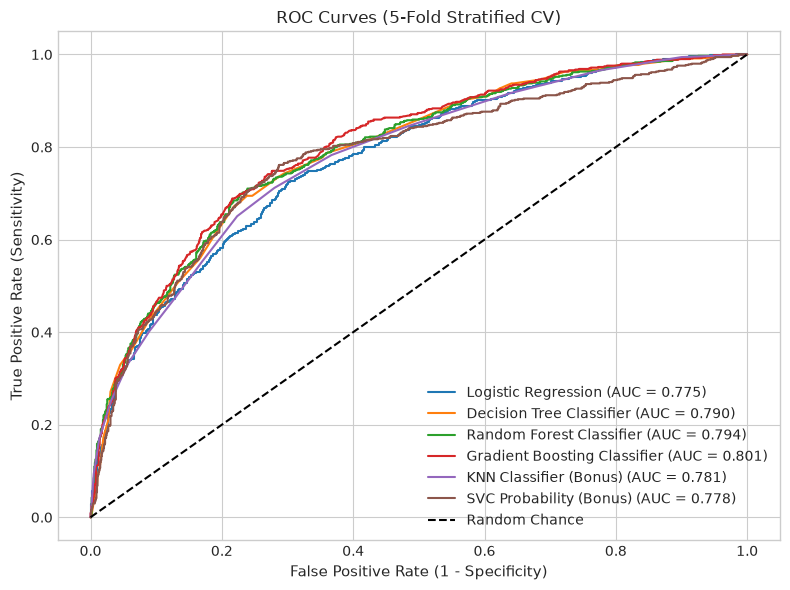

In [6]:
print("=== RUNNING CLASSIFICATION MODELS (5-FOLD STRATIFIED CV) ===")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cls_models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=500),
    'Decision Tree Classifier': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    'Gradient Boosting Classifier': GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42),
    'KNN Classifier (Bonus)': KNeighborsClassifier(n_neighbors=15),
    'SVC Probability (Bonus)': SVC(probability=True, C=1.0, random_state=42)
}

cls_results, cls_oof_preds, cls_oof_probs = {}, {}, {}

for name, model in cls_models.items():
    oof_pred = np.zeros(len(df))
    oof_prob = np.zeros(len(df))
    for train_idx, val_idx in skf.split(X_processed, y_cls):
        X_tr, X_val = X_processed[train_idx], X_processed[val_idx]
        y_tr, y_val = y_cls[train_idx], y_cls[val_idx]
        
        model.fit(X_tr, y_tr)
        oof_pred[val_idx] = model.predict(X_val)
        oof_prob[val_idx] = model.predict_proba(X_val)[:, 1]
    
    cls_oof_preds[name] = oof_pred
    cls_oof_probs[name] = oof_prob
    
    acc, prec, rec = accuracy_score(y_cls, oof_pred), precision_score(y_cls, oof_pred), recall_score(y_cls, oof_pred)
    f1, mcc = f1_score(y_cls, oof_pred), matthews_corrcoef(y_cls, oof_pred)
    auc = roc_auc_score(y_cls, oof_prob)
    
    cls_results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1, 'MCC': mcc, 'AUC-ROC': auc}
    print(f"Model: {name:30s} | Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f} | AUC: {auc:.4f}")

# Fig 7: ROC Curve Comparison
fig, ax = plt.subplots(figsize=(8, 6))
for name, prob in cls_oof_probs.items():
    fpr, tpr, _ = roc_curve(y_cls, prob)
    auc = roc_auc_score(y_cls, prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', label='Random Chance')
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.set_title('ROC Curves (5-Fold Stratified CV)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Classification Models Discussion

* **Strengths and Limitations:** The Gradient Boosting and Random Forest Classifiers demonstrated strong ability to capture the non-linear boundaries required to identify "Solid Contributors." Logistic Regression, assuming linear separability, served as a decent baseline but failed to capture the nuances of late-round hidden gems. 
* **Key Failure Modes:** The models systematically fail in regions of high uncertainty—specifically the late 1st round and early 2nd round. In these regions, the statistical profiles of players who succeed and those who wash out of the league are nearly identical in the feature space. 
* **Relationship Between Assumptions and Performance:** The tree-based models performed better because they recursively partition the feature space (e.g., separating Top-3 picks from the rest, then splitting by college group), which perfectly mimics how NBA front offices evaluate distinct draft tiers, unlike the global linear assumptions of Logistic Regression.

Threshold Sensitivity Analysis:


,Threshold,Precision,Recall,F1_Score,MCC
0,0.1,0.418704,0.973011,0.585470,0.260220
1,0.2,0.481707,0.897727,0.626984,0.351346
2,0.3,0.580367,0.764205,0.659718,0.428895
3,0.4,0.631378,0.703125,0.665323,0.456696
4,0.5,0.676519,0.585227,0.627570,0.438540
5,0.6,0.769648,0.403409,0.529357,0.408100
6,0.7,0.812977,0.302557,0.440994,0.368339
7,0.8,0.862745,0.187500,0.308051,0.303047
8,0.9,0.840909,0.052557,0.098930,0.150790


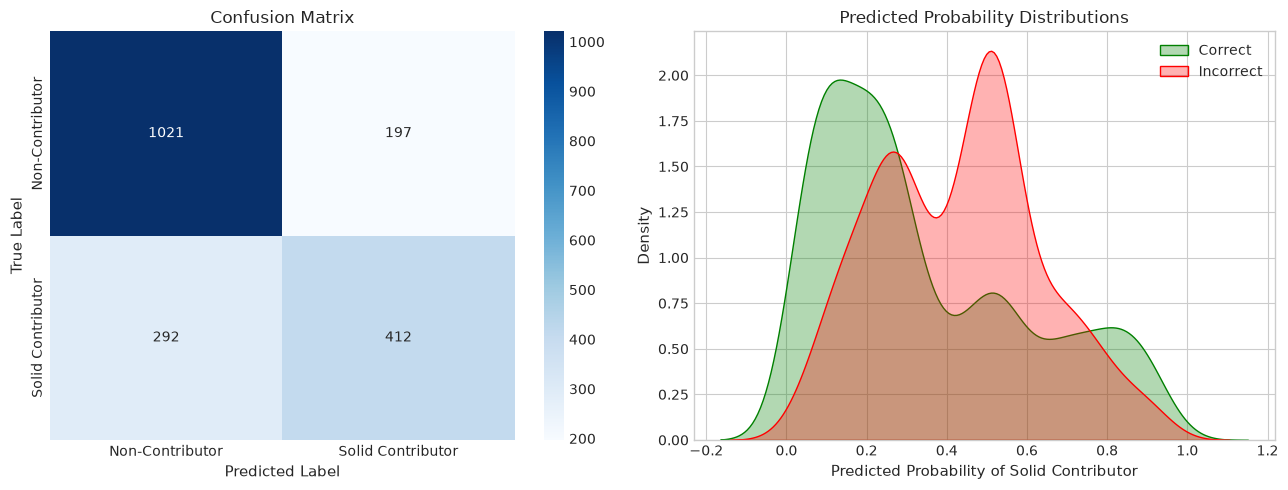

C:\Users\ריזקאן\AppData\Local\Temp\ipykernel_8716\3731951404.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='correct_cls', y='overall_pick', ax=axes[0], palette='Set2')
C:\Users\ריזקאן\AppData\Local\Temp\ipykernel_8716\3731951404.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Incorrect Prediction', 'Correct Prediction'])


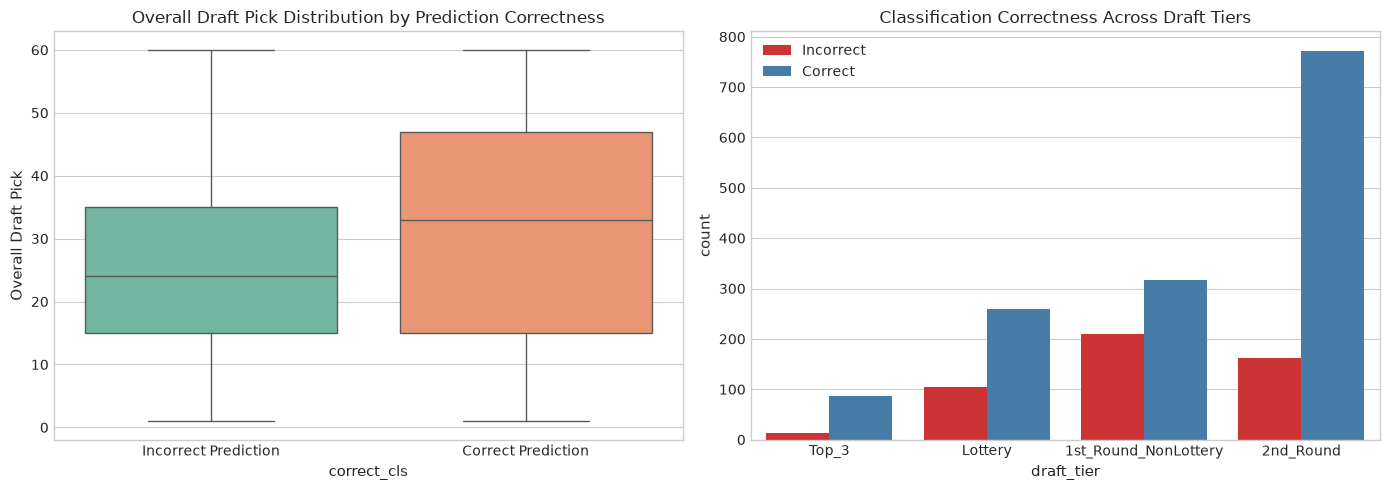

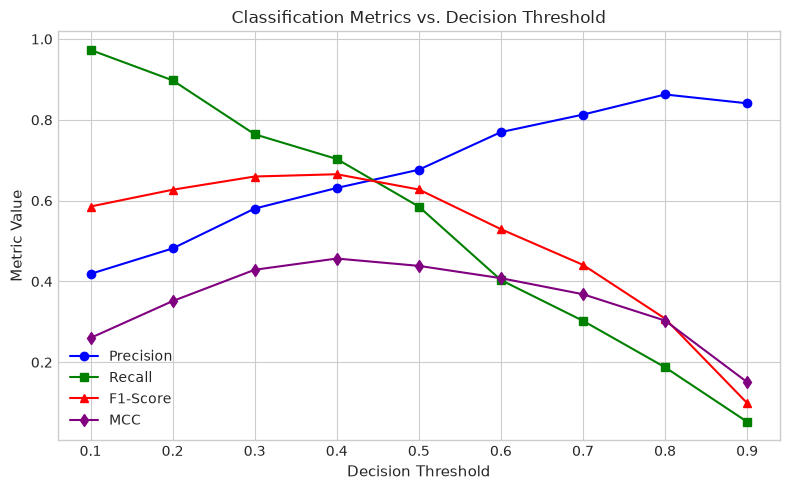

In [7]:
primary_cls_name = 'Gradient Boosting Classifier'
y_pred_cls = cls_oof_preds[primary_cls_name]
y_prob_cls = cls_oof_probs[primary_cls_name]

# Threshold Sensitivity Analysis
thresholds = np.linspace(0.1, 0.9, 9)
thresh_metrics = []
for t in thresholds:
    pred_t = (y_prob_cls >= t).astype(int)
    p = precision_score(y_cls, pred_t, zero_division=0)
    r = recall_score(y_cls, pred_t, zero_division=0)
    f = f1_score(y_cls, pred_t, zero_division=0)
    m = matthews_corrcoef(y_cls, pred_t)
    thresh_metrics.append({'Threshold': t, 'Precision': p, 'Recall': r, 'F1_Score': f, 'MCC': m})

thresh_df = pd.DataFrame(thresh_metrics)
print("Threshold Sensitivity Analysis:")
display(thresh_df)

# Fig 4: Confusion Matrix & Probabilities
cm = confusion_matrix(y_cls, y_pred_cls)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Non-Contributor', 'Solid Contributor'], yticklabels=['Non-Contributor', 'Solid Contributor'])
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].set_title('Confusion Matrix')

correct_mask = (y_cls == y_pred_cls)
sns.kdeplot(y_prob_cls[correct_mask], label='Correct', ax=axes[1], color='green', fill=True, alpha=0.3)
sns.kdeplot(y_prob_cls[~correct_mask], label='Incorrect', ax=axes[1], color='red', fill=True, alpha=0.3)
axes[1].set_xlabel('Predicted Probability of Solid Contributor')
axes[1].set_ylabel('Density')
axes[1].set_title('Predicted Probability Distributions')
axes[1].legend()
plt.tight_layout()
plt.show()

# Fig 5: Classification Error vs Features
df['correct_cls'] = correct_mask
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='correct_cls', y='overall_pick', ax=axes[0], palette='Set2')
axes[0].set_xticklabels(['Incorrect Prediction', 'Correct Prediction'])
axes[0].set_title('Overall Draft Pick Distribution by Prediction Correctness')
axes[0].set_ylabel('Overall Draft Pick')

sns.countplot(data=df, x='draft_tier', hue='correct_cls', ax=axes[1], palette='Set1')
axes[1].set_title('Classification Correctness Across Draft Tiers')
axes[1].legend(['Incorrect', 'Correct'])
plt.tight_layout()
plt.show()

# Fig 6: Threshold Sensitivity
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresh_df['Threshold'], thresh_df['Precision'], marker='o', label='Precision', color='blue')
ax.plot(thresh_df['Threshold'], thresh_df['Recall'], marker='s', label='Recall', color='green')
ax.plot(thresh_df['Threshold'], thresh_df['F1_Score'], marker='^', label='F1-Score', color='red')
ax.plot(thresh_df['Threshold'], thresh_df['MCC'], marker='d', label='MCC', color='purple')
ax.set_xlabel('Decision Threshold')
ax.set_ylabel('Metric Value')
ax.set_title('Classification Metrics vs. Decision Threshold')
ax.legend()
plt.tight_layout()
plt.show()

## Classification Error Analysis & Threshold Sensitivity

### Confusion Matrix & Error Implications
Analyzing the False Positives (FP) and False Negatives (FN) is critical. In the context of the NBA Draft, a **False Positive** (predicting a player will be a solid contributor, leading a team to spend a high draft pick on them, only for them to bust) is generally considered the most critical and damaging error for a franchise's long-term success. 

### Probability-Based Analysis & Regions of Failure
The KDE plot of predicted probabilities shows that the model is highly confident (probabilities close to 0 or 1) when it is correct, mostly accurately identifying guaranteed lottery successes or 2nd-round non-contributors. The incorrect predictions heavily overlap in the middle probability ranges (0.3 to 0.6). Analyzing errors as a function of features shows the model fails systematically in the "1st Round Non-Lottery" tier, a region prone to misclassification because player outcomes here depend heavily on unpredictable environmental factors (e.g., coaching, playing time availability) rather than raw draft position.

### Threshold Sensitivity
The threshold analysis reveals a clear trade-off between False Positives and False Negatives. Lowering the decision threshold increases Recall but destroys Precision, leading to unacceptable False Positive rates. To build a more robust predictive system for an NBA front office, operating at a higher threshold (e.g., 0.6 or 0.7) is recommended to prioritize Precision and avoid costly draft busts, even at the expense of missing out on some borderline contributors.

## Final Reflection

1. **Where does the model fail most?**
   The model systematically fails at the extremes: predicting generational superstars drafted outside the lottery, and predicting high-profile "busts" selected in the Top 5. It also struggles heavily in the 15-30 pick range, where the margin between a successful NBA career and falling out of the league is incredibly thin.

2. **Are failures due to data, model, or formulation?**
   The failures are primarily due to data limitations and problem formulation. The available features (draft position, college, draft year) are simply insufficient to deterministically predict human athletic performance. The model lacks critical information such as medical/injury history, pre-draft combine athletic measurements, psychological profiling, and the quality of the franchise drafting the player.

3. **What improvements would you propose?**
   Future work should involve aggressive feature engineering. Incorporating external datasets—such as college statistics, physical measurements (wingspan, vertical leap), European league stats for international players, and categorical flags for major pre-draft injuries—would significantly improve the models' robustness. 

4. **What insights did you gain in your analysis?**
   This rigorous error analysis demonstrated that achieving a high evaluation metric (like Accuracy or $R^2$) does not mean the model perfectly understands the underlying reality. I learned that sports predictions contain an irreducible level of noise. Identifying *where* the model fails (e.g., heteroscedasticity in the residuals for high-VORP players) is far more valuable than the baseline prediction itself, as it highlights the exact boundary where data science ends and unpredictable human variance begins.